In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

In [4]:
df = pd.read_csv("../HW8/Waves_2023.txt", sep=r"\s+", na_values={"WVHT": 99, "DPD": 99, "APD": 99, "MWD": 999, "WTMP": 999})
df = df.dropna(subset=["WVHT", "DPD", "APD", "MWD", "WTMP"])
X = df[["DPD", "APD", "MWD", "WTMP"]]
y = df["WVHT"]
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

In [5]:
models = {"Linear regression": LinearRegression(), "XGBoost (25)": XGBRegressor(n_estimators=25, objective="reg:squarederror", random_state=42, n_jobs=4)}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append({"Model": name, "Train RMSE (m)": np.sqrt(mean_squared_error(y_train, model.predict(X_train))), "Validation RMSE (m)": np.sqrt(mean_squared_error(y_val, model.predict(X_val))), "Test RMSE (m)": np.sqrt(mean_squared_error(y_test, model.predict(X_test)))})
pd.DataFrame(results).round(4)

,Model,Train RMSE (m),Validation RMSE (m),Test RMSE (m)
0,Linear regression,0.4448,0.4367,0.4410
1,XGBoost (25),0.2677,0.3069,0.3069


1. XGBoost Better on all three set of data.
2. square loss
3. default values

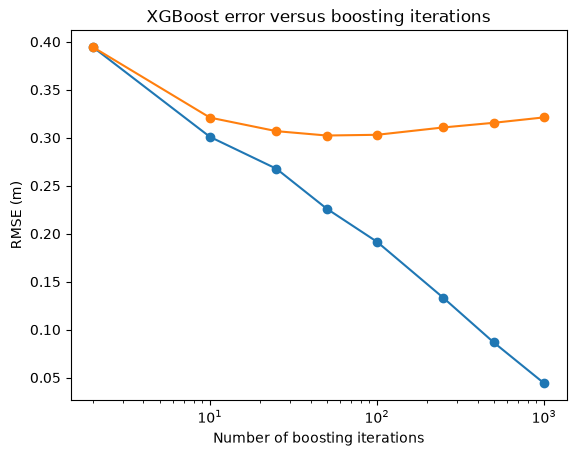

In [8]:
counts = [2, 10, 25, 50, 100, 250, 500, 1000]
train_errors = []
val_errors = []
for n in counts:
    model = XGBRegressor(n_estimators=n, objective="reg:squarederror", random_state=42, n_jobs=4)
    model.fit(X_train, y_train)
    train_errors.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
    val_errors.append(np.sqrt(mean_squared_error(y_val, model.predict(X_val))))
plt.semilogx(counts, train_errors, "o-", label="Training")
plt.semilogx(counts, val_errors, "o-", label="Validation")
plt.xlabel("Number of boosting iterations")
plt.ylabel("RMSE (m)")
plt.title("XGBoost error versus boosting iterations")
plt.show()

4. training error decrease as iteration, while validation decrease and slowly increase at around 0.3-0.35.
5. yes, validation stop decrease and begin to increase slightly which is sigbn of overfitting. 

In [11]:
model = XGBRegressor(n_estimators=1000, early_stopping_rounds=10)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print(model.best_iteration)

45


6. 45 is the bext iteration, stopped there. 